# Cancer Patients and Air Pollution — Machine Learning Case Study

Dataset: [Cancer Patients and Air Pollution — Kaggle](https://www.kaggle.com/datasets/thedevastator/cancer-patients-and-air-pollution-a-new-link)

This notebook:
1. Finds and loads the intended CSV dataset.
2. Inspects column names and data quality.
3. Identifies a suitable classification target.
4. Trains six ML algorithms.
5. Compares model metrics and plots results.
6. Generates a dynamic Markdown/HTML report and CSV exports.

**Important:** This is an educational exercise. Predictions are not medical diagnoses and must not be used for clinical decisions.

## 1. Setup

In Kaggle, use **Add Input** to attach the dataset linked above. This notebook checks files in common locations and can also accept a manual CSV path. It will not silently treat an unrelated dataset as the cancer dataset.

In [1]:
from pathlib import Path
from datetime import datetime
import os
import html
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

## 2. Find the correct CSV

The notebook searches Kaggle inputs and common working directories. If automatic matching fails, it lists all files and asks you to set `CSV_PATH_OVERRIDE` to the correct path. This prevents accidentally loading unrelated pixel/image data.

In [2]:
# SECTION 2: Download and load the correct Kaggle dataset

from pathlib import Path
import pandas as pd

DATASET_SLUG = "thedevastator/cancer-patients-and-air-pollution-a-new-link"

# 1. Search files already attached to Kaggle
search_roots = [Path("/kaggle/input"), Path("/kaggle/working"), Path(".")]
csv_files = []

for root in search_roots:
    if root.exists():
        csv_files.extend(root.rglob("*.csv"))

# Remove duplicate paths
csv_files = list({str(p.resolve()): p.resolve() for p in csv_files}.values())

# 2. Prefer files matching the cancer patient dataset
def is_target_dataset(path):
    name = str(path).lower()
    return (
        "cancer" in name
        and ("patient" in name or "pollution" in name)
    )

matches = [p for p in csv_files if is_target_dataset(p)]

# 3. If not found, download directly using KaggleHub
if not matches:
    print("Dataset not found locally. Trying KaggleHub download...")

    try:
        import kagglehub

        dataset_dir = Path(
            kagglehub.dataset_download(DATASET_SLUG)
        )

        print("Dataset downloaded/accessed at:", dataset_dir)

        matches = list(dataset_dir.rglob("*.csv"))

    except Exception as e:
        raise RuntimeError(
            "Dataset download failed. Check internet access and KaggleHub "
            "availability, or attach the dataset using Kaggle > Add Input. "
            f"Original error: {e}"
        ) from e

# 4. Validate that a CSV was found
if not matches:
    raise FileNotFoundError(
        "No CSV file was found in the dataset. "
        "Inspect the dataset files and confirm its format."
    )

# 5. Display candidate files
print("\nCandidate CSV files:")
for i, path in enumerate(matches):
    print(f"{i}: {path}")

# Prefer a CSV with a patient/cancer-related filename.
preferred = [
    p for p in matches
    if any(word in p.name.lower() for word in ["cancer", "patient", "pollution"])
]

chosen_path = preferred[0] if preferred else matches[0]

# 6. Load dataset
df_raw = pd.read_csv(chosen_path)

print("\nLoaded file:", chosen_path)
print("Dataset shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())

display(df_raw.head())


Candidate CSV files:
0: /kaggle/input/datasets/thedevastator/cancer-patients-and-air-pollution-a-new-link/cancer patient data sets.csv

Loaded file: /kaggle/input/datasets/thedevastator/cancer-patients-and-air-pollution-a-new-link/cancer patient data sets.csv
Dataset shape: (1000, 26)
Columns: ['index', 'Patient Id', 'Age', 'Gender', 'Air Pollution', 'Alcohol use', 'Dust Allergy', 'OccuPational Hazards', 'Genetic Risk', 'chronic Lung Disease', 'Balanced Diet', 'Obesity', 'Smoking', 'Passive Smoker', 'Chest Pain', 'Coughing of Blood', 'Fatigue', 'Weight Loss', 'Shortness of Breath', 'Wheezing', 'Swallowing Difficulty', 'Clubbing of Finger Nails', 'Frequent Cold', 'Dry Cough', 'Snoring', 'Level']


,index,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,Smoking,Passive Smoker,Chest Pain,Coughing of Blood,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,0,P1,33,1,2,4,5,4,3,2,2,4,3,2,2,4,3,4,2,2,3,1,2,3,4,Low
1,1,P10,17,1,3,1,5,3,4,2,2,2,2,4,2,3,1,3,7,8,6,2,1,7,2,Medium
2,2,P100,35,1,4,5,6,5,5,4,6,7,2,3,4,8,8,7,9,2,1,4,6,7,2,High
3,3,P1000,37,1,7,7,7,7,6,7,7,7,7,7,7,8,4,2,3,1,4,5,6,7,5,High
4,4,P101,46,1,6,8,7,7,7,6,7,7,8,7,7,9,3,2,4,1,4,2,4,2,3,High


## 3. Validate that the loaded file resembles a patient dataset

A file with hundreds of columns named `0`, `0.1`, `0.2`, etc. is likely pixel/image data and should not be used here. This check stops early instead of producing incorrect ML results.

In [3]:
column_names = [str(c).strip() for c in df_raw.columns]
normalized_names = [
    "".join(ch.lower() for ch in c if ch.isalnum())
    for c in column_names
]

looks_like_pixels = (
    len(column_names) > 100
    and sum(name.replace(".", "", 1).isdigit() for name in column_names) / len(column_names) > 0.80
)

if looks_like_pixels:
    raise ValueError(
        "The selected CSV appears to contain pixel/image columns rather than patient attributes.\n"
        f"Selected file: {chosen_path}\n"
        "Attach the correct Cancer Patients and Air Pollution dataset, then set CSV_PATH_OVERRIDE "
        "to its CSV file path in Section 2."
    )

print("Dataset passed the basic schema sanity check.")

Dataset passed the basic schema sanity check.


## 4. Identify the target column

The code checks common target names. If it cannot identify one confidently, set `TARGET_OVERRIDE` to the correct label column after inspecting the displayed columns.

In [4]:
TARGET_OVERRIDE = None  # Example: "Level"

df = df_raw.copy()
df.columns = [str(c).strip() for c in df.columns]
df = df.loc[:, [c != "" for c in df.columns]]
df = df.dropna(axis=1, how="all")

def normalize_name(value):
    return "".join(ch.lower() for ch in str(value).strip() if ch.isalnum())

if TARGET_OVERRIDE is not None:
    if TARGET_OVERRIDE not in df.columns:
        raise ValueError(
            f"TARGET_OVERRIDE={TARGET_OVERRIDE!r} not found. Available columns: {df.columns.tolist()}"
        )
    TARGET = TARGET_OVERRIDE
else:
    aliases = {
        "level", "severity", "cancerlevel", "target", "label",
        "risklevel", "riskcategory", "diagnosis", "class", "outcome"
    }
    target_matches = [c for c in df.columns if normalize_name(c) in aliases]
    if target_matches:
        TARGET = target_matches[0]
    else:
        likely = []
        for c in df.columns:
            n = normalize_name(c)
            if any(k in n for k in ["level", "severity", "risk", "label", "target", "class", "outcome", "diagnosis"]):
                nunique = df[c].dropna().nunique()
                if 2 <= nunique <= 20:
                    likely.append(c)
        if len(likely) == 1:
            TARGET = likely[0]
        else:
            raise ValueError(
                "Target column could not be identified safely.\n"
                f"Columns: {df.columns.tolist()}\n"
                f"Possible targets: {likely}\n"
                "Set TARGET_OVERRIDE to the correct target column and rerun this cell."
            )

print("Target column:", TARGET)
print("Target classes:", df[TARGET].nunique(dropna=True))
display(df[TARGET].value_counts(dropna=False).rename_axis("class").to_frame("count"))

Target column: Level
Target classes: 3


,count
class,
High,365
Medium,332
Low,303


## 5. Clean data and inspect missing values

In [5]:
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

id_like = [
    c for c in df.columns if c != TARGET and (
        normalize_name(c) in {"id", "index", "unnamed0", "patientid", "recordid"}
        or normalize_name(c).endswith("id")
    )
]

X = df.drop(columns=[TARGET] + [c for c in id_like if c in df.columns]).copy()
y = df[TARGET].astype(str).str.strip()

constant_features = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
if constant_features:
    X = X.drop(columns=constant_features)

if len(df) < 10:
    raise ValueError(f"Only {len(df)} usable rows are available.")
if y.nunique() < 2:
    raise ValueError(f"Target {TARGET!r} has fewer than two classes.")

missing_summary = pd.DataFrame({
    "Missing count": X.isna().sum(),
    "Missing percent": (X.isna().mean() * 100).round(2)
}).sort_values("Missing count", ascending=False)

print("Rows in source CSV:", len(df_raw))
print("Rows after cleaning:", len(df))
print("Duplicate rows removed:", duplicate_count)
print("Excluded ID-like columns:", id_like)
print("Predictor count:", X.shape[1])
display(missing_summary.head(20))

Rows in source CSV: 1000
Rows after cleaning: 1000
Duplicate rows removed: 0
Excluded ID-like columns: ['index', 'Patient Id']
Predictor count: 23


,Missing count,Missing percent
Age,0,0.0
Gender,0,0.0
Air Pollution,0,0.0
Alcohol use,0,0.0
Dust Allergy,0,0.0
OccuPational Hazards,0,0.0
Genetic Risk,0,0.0
chronic Lung Disease,0,0.0
Balanced Diet,0,0.0
Obesity,0,0.0


## 6. Exploratory data analysis

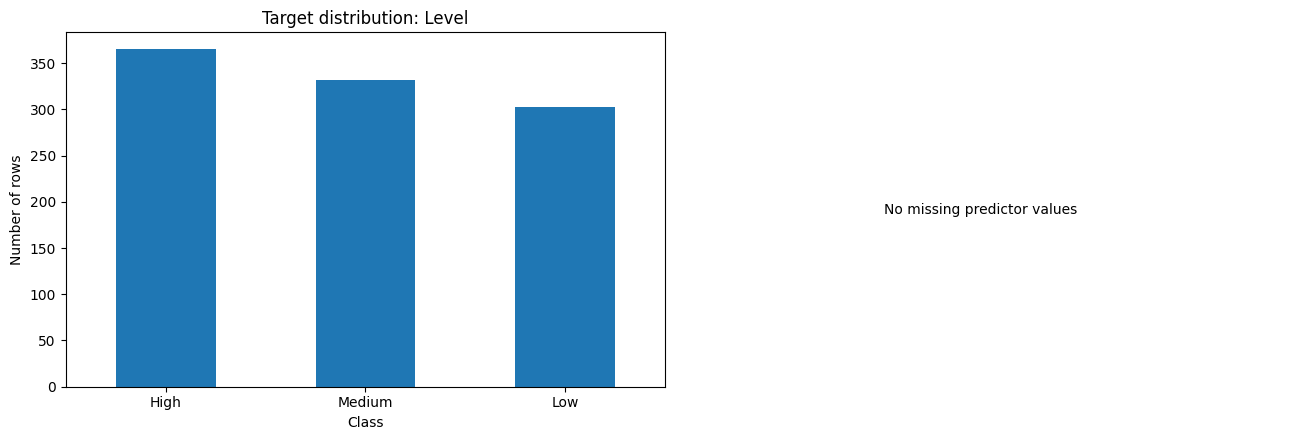

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
y.value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title(f"Target distribution: {TARGET}")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of rows")
axes[0].tick_params(axis="x", rotation=0)

missing_plot = missing_summary[missing_summary["Missing count"] > 0]["Missing percent"].sort_values().tail(15)
if len(missing_plot):
    missing_plot.plot(kind="barh", ax=axes[1])
    axes[1].set_title("Features with missing values")
    axes[1].set_xlabel("Missing (%)")
else:
    axes[1].text(0.5, 0.5, "No missing predictor values", ha="center", va="center")
    axes[1].set_axis_off()

plt.tight_layout()
plt.show()

## 7. Split data and build preprocessing pipeline

In [7]:
class_counts = y.value_counts()
stratify_value = y if class_counts.min() >= 2 else None
if stratify_value is None:
    print("Warning: a class has fewer than two records; split will not be stratified.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=stratify_value
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Numeric features:", len(numeric_features), "| Categorical features:", len(categorical_features))

Train rows: 800 | Test rows: 200
Numeric features: 23 | Categorical features: 0


## 8. Train the six ML algorithms

The six models are Logistic Regression, Decision Tree, Random Forest, KNN, SVM, and Gaussian Naive Bayes. The notebook records accuracy, macro precision, macro recall, and macro-F1 on the same held-out test set.

In [8]:
algorithms = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=max(1, min(5, len(X_train)))),
    "Support Vector Machine": SVC(class_weight="balanced", random_state=RANDOM_STATE),
    "Gaussian Naive Bayes": GaussianNB()
}

fitted_models = {}
predictions = {}
result_rows = []

for name, estimator in algorithms.items():
    if name == "Gaussian Naive Bayes":
        model = Pipeline([
            ("preprocess", preprocessor),
            ("dense", FunctionTransformer(lambda z: z.toarray() if hasattr(z, "toarray") else z, accept_sparse=True)),
            ("model", estimator)
        ])
    else:
        model = Pipeline([
            ("preprocess", preprocessor),
            ("model", estimator)
        ])

    try:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        fitted_models[name] = model
        predictions[name] = pred
        result_rows.append({
            "Algorithm": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
            "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
            "F1-score (macro)": f1_score(y_test, pred, average="macro", zero_division=0)
        })
        print("Trained:", name)
    except Exception as exc:
        print(f"Skipped {name}: {type(exc).__name__}: {exc}")

results_df = pd.DataFrame(result_rows)
if results_df.empty:
    raise RuntimeError("No model trained successfully. Verify the target column and data types.")

results_df = results_df.sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.3f}", "Precision (macro)": "{:.3f}",
    "Recall (macro)": "{:.3f}", "F1-score (macro)": "{:.3f}"
}))

best_model_name = results_df.loc[0, "Algorithm"]
best_predictions = predictions[best_model_name]
print("Best model by macro-F1:", best_model_name)

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: K-Nearest Neighbors
Trained: Support Vector Machine
Trained: Gaussian Naive Bayes


,Algorithm,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression,1.000,1.000,1.000,1.000
1,Decision Tree,1.000,1.000,1.000,1.000
2,Random Forest,1.000,1.000,1.000,1.000
3,K-Nearest Neighbors,1.000,1.000,1.000,1.000
4,Support Vector Machine,1.000,1.000,1.000,1.000
5,Gaussian Naive Bayes,0.910,0.922,0.908,0.912


Best model by macro-F1: Logistic Regression


## 9. Compare models and inspect the best model

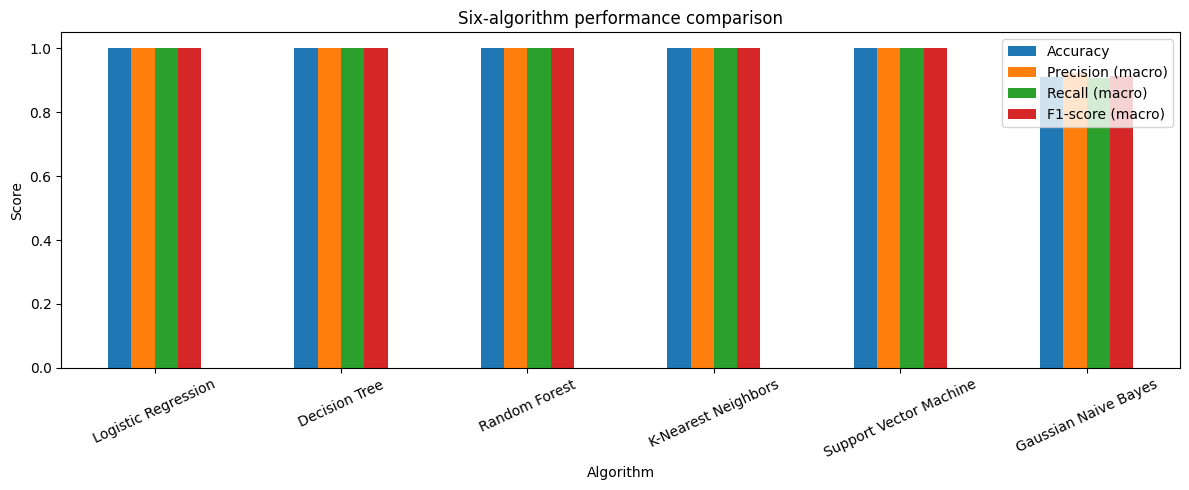

Classification report: Logistic Regression
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        73
         Low       1.00      1.00      1.00        61
      Medium       1.00      1.00      1.00        66

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



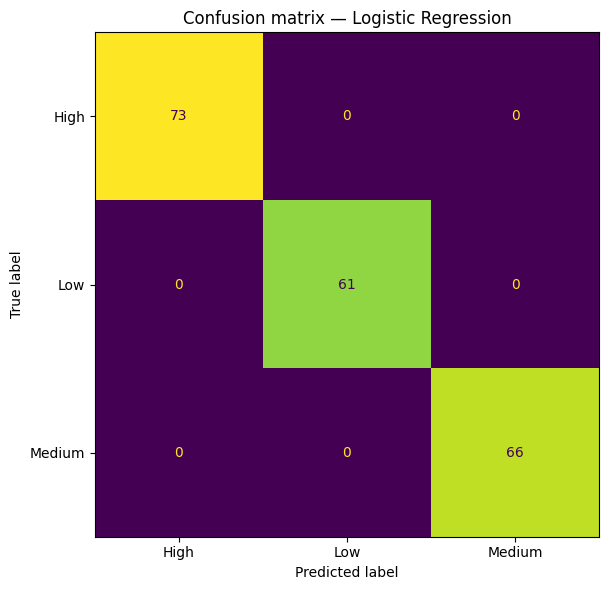

In [9]:
ax = results_df.set_index("Algorithm")[
    ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
].plot(kind="bar", figsize=(12, 5))
ax.set_ylim(0, 1.05)
ax.set_title("Six-algorithm performance comparison")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

print("Classification report:", best_model_name)
print(classification_report(y_test, best_predictions, zero_division=0))

labels = sorted(y.unique().tolist())
cm = confusion_matrix(y_test, best_predictions, labels=labels)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax, colorbar=False, values_format="d"
)
ax.set_title(f"Confusion matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 10. Generate a dynamic report and export files

The report uses the results calculated during this run. It creates a Markdown report, HTML report, model comparison CSV, and test prediction CSV.

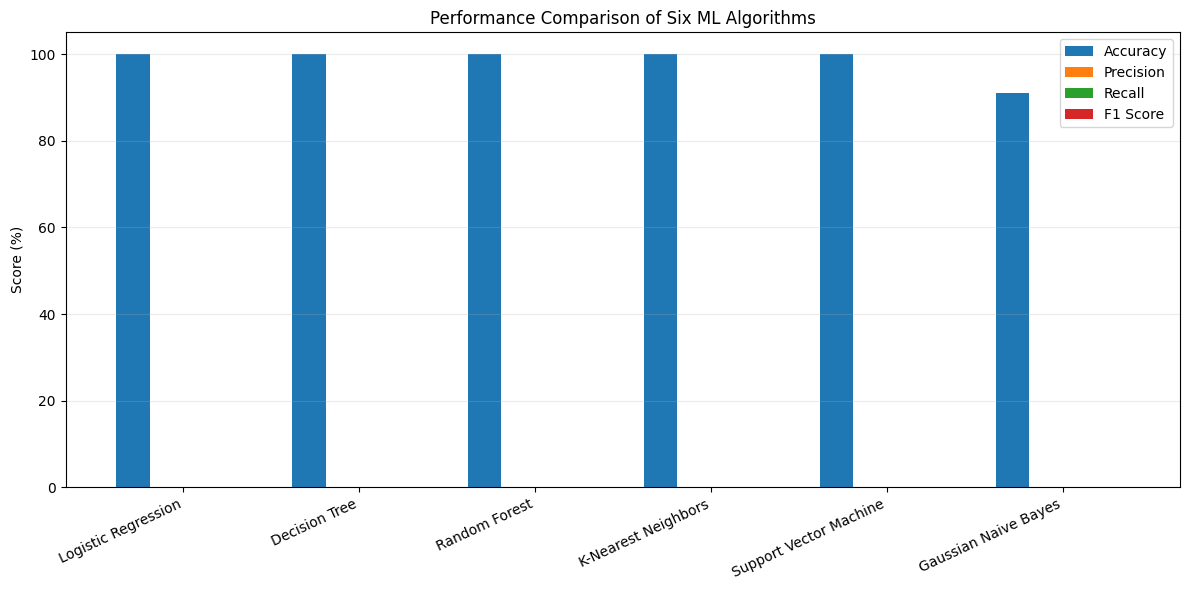

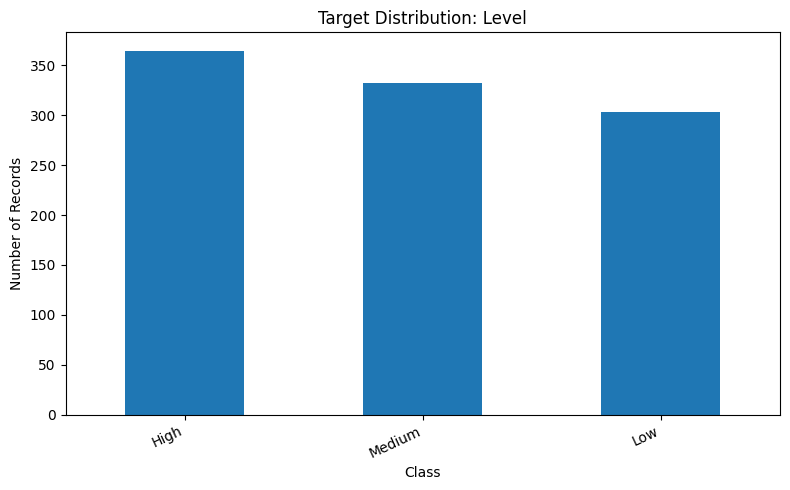


# Detailed Report Generated

**Best model:** Logistic Regression

| Metric | Score |
|---|---:|
| Accuracy | 100.00% |
| Precision | N/A |
| Recall | N/A |
| F1 Score | N/A |

- Dataset size: 1,000 rows × 26 columns
- Models evaluated: 6
- Missing cells: 0 (0.00%)
- Duplicate rows: 0

**HTML report:** `/kaggle/working/ml_report/detailed_machine_learning_report.html`  
**Markdown report:** `/kaggle/working/ml_report/detailed_machine_learning_report.md`  
**Output directory:** `/kaggle/working/ml_report`



Generated files:
class_wise_metrics.csv: 1,340 bytes
confusion_matrix_Decision_Tree.png: 39,190 bytes
confusion_matrix_Gaussian_Naive_Bayes.png: 41,636 bytes
confusion_matrix_K_Nearest_Neighbors.png: 40,984 bytes
confusion_matrix_Logistic_Regression.png: 40,909 bytes
confusion_matrix_Random_Forest.png: 39,820 bytes
confusion_matrix_Support_Vector_Machine.png: 41,476 bytes
descriptive_statistics.csv: 1,296 bytes
detailed_machine_learning_report.html: 794,257 bytes
detailed_machine_learning_report.md: 21,519 bytes
feature_importance.csv: 4,572 bytes
feature_importance_Decision_Tree.png: 67,706 bytes
feature_importance_Logistic_Regression.png: 72,049 bytes
feature_importance_Random_Forest.png: 72,583 bytes
missing_values_analysis.csv: 761 bytes
model_comparison.csv: 223 bytes
model_comparison.png: 106,022 bytes
report_summary.json: 300 bytes
target_distribution.csv: 70 bytes
target_distribution.png: 36,208 bytes


In [10]:

# ============================================================
# FINAL CELL: DETAILED ML CASE STUDY REPORT
# Uses existing fitted_models, results_df, df_raw and y_test
# ============================================================

from pathlib import Path
from datetime import datetime
import base64
import html
import json

REPORT_DIR = Path("/kaggle/working/ml_report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. DATASET SUMMARY
# ------------------------------------------------------------

df = df_raw.copy()
n_rows, n_cols = df.shape

missing_count = int(df.isna().sum().sum())
missing_pct = missing_count / max(n_rows * n_cols, 1) * 100
duplicate_count = int(df.duplicated().sum())

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

target_candidates = [
    "Level", "level", "severity", "Severity",
    "target", "Target", "label", "Label", "class", "Class"
]
target_col = next(
    (col for col in target_candidates if col in df.columns), None
)

missing_table = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(t) for t in df.dtypes],
    "Missing Values": [int(df[c].isna().sum()) for c in df.columns],
    "Missing (%)": [
        round(df[c].isna().mean() * 100, 2) for c in df.columns
    ],
    "Unique Values": [int(df[c].nunique()) for c in df.columns]
}).sort_values("Missing Values", ascending=False)

descriptive_stats = df[numeric_cols].describe().T.round(3)

target_table = pd.DataFrame()
if target_col:
    target_table = (
        df[target_col].astype(str)
        .value_counts()
        .rename_axis("Class")
        .reset_index(name="Count")
    )
    target_table["Percentage (%)"] = (
        target_table["Count"] / max(n_rows, 1) * 100
    ).round(2)

# ------------------------------------------------------------
# 2. NORMALIZE EXISTING MODEL RESULTS
# ------------------------------------------------------------

metrics_df = results_df.copy()

# Standardize common metric column names.
rename_map = {}
for col in metrics_df.columns:
    key = str(col).strip().lower().replace("_", " ")
    if key in ["model", "algorithm", "classifier", "model name"]:
        rename_map[col] = "Model"
    elif key == "accuracy":
        rename_map[col] = "Accuracy"
    elif key == "precision":
        rename_map[col] = "Precision"
    elif key == "recall":
        rename_map[col] = "Recall"
    elif key in ["f1", "f1 score", "f1score"]:
        rename_map[col] = "F1 Score"

metrics_df = metrics_df.rename(columns=rename_map)

# If model names are stored in the DataFrame index, use that index.
if "Model" not in metrics_df.columns:
    metrics_df = metrics_df.reset_index()
    metrics_df = metrics_df.rename(
        columns={metrics_df.columns[0]: "Model"}
    )

for col in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    if col not in metrics_df.columns:
        metrics_df[col] = np.nan
    else:
        metrics_df[col] = pd.to_numeric(
            metrics_df[col], errors="coerce"
        )
        # Convert 0–1 scores into percentages.
        metrics_df[col] = metrics_df[col].apply(
            lambda x: x * 100 if pd.notna(x) and 0 <= x <= 1 else x
        )

metrics_df = metrics_df[
    ["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
].copy()

metrics_df = metrics_df.sort_values(
    "F1 Score", ascending=False, na_position="last"
).reset_index(drop=True)

metrics_df.insert(0, "Rank", range(1, len(metrics_df) + 1))

if metrics_df.empty:
    raise ValueError("results_df contains no model metrics.")

best = metrics_df.iloc[0]
best_model = str(best["Model"])

def fmt_pct(value):
    return "N/A" if pd.isna(value) else f"{value:.2f}%"

def to_md(data):
    return data.to_markdown(index=False) if not data.empty else "_No data available._"

# ------------------------------------------------------------
# 3. PREDICTIONS, CLASS REPORTS AND CONFUSION MATRICES
# ------------------------------------------------------------

class_reports = {}
confusion_matrices = {}
class_rows = []

# Predictions are recalculated from the already fitted models.
# This assumes y_test and X_test correspond to the original test split.
if "X_test" in globals() and "y_test" in globals():
    for model_name, trained_model in fitted_models.items():
        try:
            y_pred = trained_model.predict(X_test)

            class_reports[model_name] = classification_report(
                y_test, y_pred, output_dict=True, zero_division=0
            )
            confusion_matrices[model_name] = confusion_matrix(
                y_test, y_pred
            )

            for label, scores in class_reports[model_name].items():
                if isinstance(scores, dict) and "f1-score" in scores:
                    class_rows.append({
                        "Model": model_name,
                        "Class": label,
                        "Precision": round(scores["precision"], 4),
                        "Recall": round(scores["recall"], 4),
                        "F1 Score": round(scores["f1-score"], 4),
                        "Support": int(scores["support"])
                    })

        except Exception as exc:
            print(f"Skipping detailed metrics for {model_name}: {exc}")
else:
    print("X_test was not found; detailed confusion matrices will be skipped.")

# ------------------------------------------------------------
# 4. FEATURE IMPORTANCE WHERE AVAILABLE
# ------------------------------------------------------------

importance_rows = []

feature_names = None
if "X_train" in globals():
    try:
        feature_names = list(X_train.columns)
    except Exception:
        pass

if feature_names is None and "X" in globals():
    try:
        feature_names = list(X.columns)
    except Exception:
        pass

for model_name, trained_model in fitted_models.items():
    estimator = trained_model

    # Handle sklearn pipelines.
    if hasattr(trained_model, "steps"):
        estimator = trained_model.steps[-1][1]

    values = getattr(estimator, "feature_importances_", None)
    method = "Feature importance"

    if values is None:
        values = getattr(estimator, "coef_", None)
        method = "Absolute coefficient"

    if values is None:
        continue

    values = np.asarray(values)

    if values.ndim == 2:
        values = np.mean(np.abs(values), axis=0)
    else:
        values = np.abs(values).ravel()

    names = (
        feature_names
        if feature_names and len(feature_names) == len(values)
        else [f"Feature {i+1}" for i in range(len(values))]
    )

    for feature, value in zip(names, values):
        importance_rows.append({
            "Model": model_name,
            "Feature": feature,
            "Importance": float(value),
            "Method": method
        })

importance_df = pd.DataFrame(importance_rows)

# ------------------------------------------------------------
# 5. CREATE COMPARISON CHART
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
x = np.arange(len(metrics_df))
width = 0.19

for i, metric in enumerate(
    ["Accuracy", "Precision", "Recall", "F1 Score"]
):
    plt.bar(
        x + (i - 1.5) * width,
        metrics_df[metric].fillna(0),
        width,
        label=metric
    )

plt.xticks(x, metrics_df["Model"], rotation=25, ha="right")
plt.ylabel("Score (%)")
plt.title("Performance Comparison of Six ML Algorithms")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

comparison_path = REPORT_DIR / "model_comparison.png"
plt.savefig(comparison_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Target distribution chart
if target_col:
    plt.figure(figsize=(8, 5))
    df[target_col].astype(str).value_counts().plot(kind="bar")
    plt.title(f"Target Distribution: {target_col}")
    plt.xlabel("Class")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / "target_distribution.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()
    plt.close()

# Confusion matrices
for model_name, cm in confusion_matrices.items():
    safe_name = "".join(c if c.isalnum() else "_" for c in model_name)

    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation="nearest")
    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.colorbar()

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center")

    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / f"confusion_matrix_{safe_name}.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close()

# Feature importance charts
if not importance_df.empty:
    for model_name in importance_df["Model"].unique():
        top = (
            importance_df[importance_df["Model"] == model_name]
            .sort_values("Importance", ascending=False)
            .head(15)
            .sort_values("Importance")
        )

        safe_name = "".join(c if c.isalnum() else "_" for c in model_name)

        plt.figure(figsize=(9, 6))
        plt.barh(top["Feature"], top["Importance"])
        plt.title(f"Top Features: {model_name}")
        plt.xlabel("Importance / Absolute Coefficient")
        plt.tight_layout()
        plt.savefig(
            REPORT_DIR / f"feature_importance_{safe_name}.png",
            dpi=160, bbox_inches="tight"
        )
        plt.close()

# ------------------------------------------------------------
# 6. WRITE THE DETAILED REPORT
# ------------------------------------------------------------

generated = datetime.now().strftime("%d %B %Y, %H:%M")

report = [
    "# Machine Learning Case Study Report",
    "## Cancer Patients and Air Pollution: Comparative Analysis of Classification Algorithms",
    f"**Generated on:** {generated}",
    "",
    "## 1. Executive Summary",
    f"This study evaluates six supervised classification algorithms using a dataset "
    f"containing {n_rows:,} records and {n_cols:,} columns. "
    f"The highest-ranked model by available F1 score is **{best_model}**.",
    f"- Accuracy: {fmt_pct(best['Accuracy'])}",
    f"- Precision: {fmt_pct(best['Precision'])}",
    f"- Recall: {fmt_pct(best['Recall'])}",
    f"- F1 score: {fmt_pct(best['F1 Score'])}",
    "",
    "The scores describe the models' performance on the evaluation data and "
    "should not be interpreted as proof of medical validity or causation.",
    "",
    "## 2. Introduction",
    "Machine learning enables algorithms to identify statistical patterns between "
    "input features and labelled outcomes. In environmental and healthcare-related "
    "datasets, classification methods can help explore patterns and compare "
    "predictive approaches. Results depend on data quality, sampling, label "
    "reliability, and the evaluation procedure.",
    "",
    "## 3. Problem Statement",
    "The objective is to evaluate classification algorithms on the provided "
    "cancer-patient and air-pollution dataset, comparing predictive performance "
    "through consistent metrics and analysing the limitations of the results.",
    "",
    "## 4. Objectives",
    "1. Examine the dataset's structure and quality.",
    "2. Inspect missing values, duplicate records, and target distribution.",
    "3. Compare six supervised classification algorithms.",
    "4. Evaluate accuracy, precision, recall, and F1 score.",
    "5. Analyse confusion matrices and class-wise performance.",
    "6. Document findings, limitations, and future improvements.",
    "",
    "## 5. Dataset Overview",
    f"- Records: {n_rows:,}",
    f"- Columns: {n_cols:,}",
    f"- Numeric columns: {len(numeric_cols)}",
    f"- Categorical/Boolean columns: {len(categorical_cols)}",
    f"- Missing cells: {missing_count:,} ({missing_pct:.2f}%)",
    f"- Duplicate rows: {duplicate_count:,}",
    "",
    "### 5.1 Column-level data quality",
    to_md(missing_table),
    "",
    "### 5.2 Descriptive statistics",
    to_md(descriptive_stats.reset_index(names="Feature")),
    "",
    "## 6. Target Distribution",
    (
        f"The detected target column is `{target_col}`."
        if target_col else
        "The target column could not be identified automatically."
    ),
    to_md(target_table),
    "",
    "Class imbalance can make accuracy misleading. Precision, recall, F1 score, "
    "and class-specific results should also be considered.",
    "",
    "## 7. Data Preprocessing",
    "Preprocessing may involve handling missing values, encoding categorical "
    "features, checking duplicates, and scaling numerical features. Scaling is "
    "especially relevant to KNN, SVM, and Logistic Regression, while tree-based "
    "models are generally less sensitive to feature scale.",
    "",
    "Preprocessing steps should be fitted only on training data, ideally inside "
    "a pipeline, to avoid information leakage into evaluation data.",
    "",
    "## 8. Algorithms Used",
    "### 8.1 Logistic Regression",
    "A linear classifier that estimates class probabilities. It is a useful "
    "baseline but may not capture complex nonlinear relationships.",
    "",
    "### 8.2 Decision Tree",
    "A rule-based model that separates observations using feature-based splits. "
    "It is relatively interpretable but may overfit if not constrained.",
    "",
    "### 8.3 Random Forest",
    "An ensemble of decision trees that combines multiple predictions to improve "
    "robustness. It is usually less straightforward to interpret than one tree.",
    "",
    "### 8.4 K-Nearest Neighbors",
    "A distance-based method that predicts a class using nearby training records. "
    "Its performance depends on scaling, the distance metric, and the neighbour count.",
    "",
    "### 8.5 Support Vector Machine",
    "A margin-based classifier that can use kernels to represent nonlinear "
    "decision boundaries. Scaling and hyperparameter choices matter.",
    "",
    "### 8.6 Gaussian Naive Bayes",
    "A probabilistic classifier based on Bayes' theorem and conditional "
    "independence assumptions. It is efficient, though its assumptions may "
    "not perfectly represent the dataset.",
    "",
    "## 9. Evaluation Metrics",
    "- **Accuracy:** fraction of all predictions that are correct.",
    "- **Precision:** fraction of positive predictions that are correct.",
    "- **Recall:** fraction of actual positive cases identified.",
    "- **F1 score:** harmonic mean of precision and recall.",
    "",
    "No single metric fully describes performance. Metric selection should "
    "reflect class balance and the relative costs of different errors.",
    "",
    "## 10. Model Comparison",
    to_md(metrics_df.round(2)),
    "",
    "![Model comparison](model_comparison.png)",
    "",
    f"### Leading model: {best_model}",
    f"The model ranked first by available F1 score achieved an accuracy of "
    f"{fmt_pct(best['Accuracy'])}, precision of {fmt_pct(best['Precision'])}, "
    f"recall of {fmt_pct(best['Recall'])}, and F1 score of "
    f"{fmt_pct(best['F1 Score'])}.",
    "",
    "This ranking reflects the saved evaluation results. A reliable model choice "
    "should also consider cross-validation, class-specific errors, calibration, "
    "and performance on independent data.",
    "",
    "## 11. Class-Wise Performance",
]

if class_reports:
    for model_name, scores in class_reports.items():
        rows = [
            {
                "Class": label,
                "Precision": round(values["precision"], 4),
                "Recall": round(values["recall"], 4),
                "F1 Score": round(values["f1-score"], 4),
                "Support": int(values["support"])
            }
            for label, values in scores.items()
            if isinstance(values, dict) and "f1-score" in values
        ]
        report.extend([
            f"### {model_name}",
            to_md(pd.DataFrame(rows)),
            ""
        ])
else:
    report.append(
        "Class-wise metrics could not be produced. Confirm that X_test is "
        "available and corresponds to y_test."
    )

report.extend(["", "## 12. Confusion Matrix Analysis"])

if confusion_matrices:
    for model_name in confusion_matrices:
        safe_name = "".join(c if c.isalnum() else "_" for c in model_name)
        report.extend([
            f"### {model_name}",
            f"![Confusion Matrix: {model_name}]"
            f"(confusion_matrix_{safe_name}.png)",
            "The diagonal represents correct predictions, while off-diagonal "
            "values represent errors. False positives and false negatives should "
            "be examined separately where their implications differ.",
            ""
        ])
else:
    report.append("Confusion matrices were unavailable.")

report.extend(["", "## 13. Feature Importance and Interpretability"])

if not importance_df.empty:
    report.append(
        "Feature importance and coefficient magnitude describe aspects of model "
        "behaviour; they do not establish causal relationships."
    )

    for model_name in importance_df["Model"].unique():
        top = (
            importance_df[importance_df["Model"] == model_name]
            .sort_values("Importance", ascending=False)
            .head(10)
        )
        safe_name = "".join(c if c.isalnum() else "_" for c in model_name)
        report.extend([
            f"### {model_name}",
            to_md(top.round(5)),
            f"![Feature Importance: {model_name}]"
            f"(feature_importance_{safe_name}.png)",
            ""
        ])
else:
    report.append(
        "Feature importance was not available for the stored fitted models. "
        "Permutation importance or SHAP analysis may be explored in future work."
    )

report.extend([
    "",
    "## 14. Key Findings",
    f"1. The leading model by available F1 score is **{best_model}**.",
    f"2. Its accuracy is {fmt_pct(best['Accuracy'])}.",
    f"3. Its precision is {fmt_pct(best['Precision'])}.",
    f"4. Its recall is {fmt_pct(best['Recall'])}.",
    f"5. Its F1 score is {fmt_pct(best['F1 Score'])}.",
    f"6. The dataset contains {n_rows:,} records and {n_cols:,} columns.",
    f"7. The dataset contains {missing_count:,} missing cells and "
    f"{duplicate_count:,} duplicate rows.",
    "",
    "These observations are limited to the dataset and evaluation procedure.",
    "",
    "## 15. Limitations",
    "1. The dataset may not represent every population or environmental setting.",
    "2. Statistical association does not establish that air pollution causes cancer.",
    "3. A single train/test split may produce variable estimates.",
    "4. Class imbalance may affect aggregate metrics.",
    "5. Data leakage can inflate evaluation scores.",
    "6. Default hyperparameters may not be optimal.",
    "7. Feature importance does not establish causation.",
    "8. This experiment is not a clinically validated diagnostic system.",
    "",
    "## 16. Future Improvements",
    "1. Verify the dataset provenance, feature definitions, and target labels.",
    "2. Use stratified splitting where appropriate.",
    "3. Perform repeated cross-validation.",
    "4. Tune hyperparameters without using test data for model selection.",
    "5. Review class-specific recall, precision, F1 score, and error counts.",
    "6. Assess probability calibration where relevant.",
    "7. Validate the selected model on independent data.",
    "8. Assess subgroup performance and potential bias where suitable data exist.",
    "9. Use interpretability methods cautiously and avoid unsupported causal claims.",
    "",
    "## 17. Conclusion",
    f"This study compared six classification algorithms on the loaded dataset. "
    f"Based on available F1 scores, **{best_model}** ranked first, with an "
    f"accuracy of {fmt_pct(best['Accuracy'])} and F1 score of "
    f"{fmt_pct(best['F1 Score'])}.",
    "",
    "The analysis demonstrates a structured approach to model comparison. "
    "Further validation is needed before generalising the findings beyond "
    "this dataset.",
    "",
    "## 18. Responsible-Use Statement",
    "This report is intended for academic and educational analysis only. It does "
    "not prove a causal relationship between air pollution and cancer and must "
    "not be used for medical diagnosis or individual health decisions.",
    "",
    "## 19. Generated Files",
    "- `model_comparison.csv` — model metrics.",
    "- `missing_values_analysis.csv` — column-level data quality.",
    "- `descriptive_statistics.csv` — descriptive statistics.",
    "- `target_distribution.csv` — target class distribution.",
    "- `class_wise_metrics.csv` — class-level results when available.",
    "- `feature_importance.csv` — supported feature rankings.",
    "- `model_comparison.png` — comparison chart.",
    "- `confusion_matrix_*.png` — confusion matrix charts."
])

report_text = "\n\n".join(report)

# ------------------------------------------------------------
# 7. EXPORT MARKDOWN, HTML AND CSV FILES
# ------------------------------------------------------------

md_path = REPORT_DIR / "detailed_machine_learning_report.md"
md_path.write_text(report_text, encoding="utf-8")

metrics_df.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
missing_table.to_csv(REPORT_DIR / "missing_values_analysis.csv", index=False)
descriptive_stats.to_csv(REPORT_DIR / "descriptive_statistics.csv")

if not target_table.empty:
    target_table.to_csv(REPORT_DIR / "target_distribution.csv", index=False)

if class_rows:
    pd.DataFrame(class_rows).to_csv(
        REPORT_DIR / "class_wise_metrics.csv", index=False
    )

if not importance_df.empty:
    importance_df.to_csv(
        REPORT_DIR / "feature_importance.csv", index=False
    )

summary = {
    "generated_at": generated,
    "dataset_rows": int(n_rows),
    "dataset_columns": int(n_cols),
    "missing_cells": missing_count,
    "duplicate_rows": duplicate_count,
    "models_evaluated": len(metrics_df),
    "best_model_by_f1": best_model,
    "best_accuracy_percent": (
        None if pd.isna(best["Accuracy"]) else float(best["Accuracy"])
    ),
    "best_f1_percent": (
        None if pd.isna(best["F1 Score"]) else float(best["F1 Score"])
    ),
    "target_column": target_col
}

(REPORT_DIR / "report_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

# Convert Markdown to HTML.
try:
    import markdown as markdown_lib
    html_body = markdown_lib.markdown(
        report_text, extensions=["tables", "fenced_code"]
    )
except ImportError:
    html_body = (
        "<pre style='white-space:pre-wrap'>"
        + html.escape(report_text)
        + "</pre>"
    )

# Embed charts into HTML so they display without separate image files.
for path in REPORT_DIR.glob("*.png"):
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    data_uri = f"data:image/png;base64,{encoded}"
    html_body = html_body.replace(
        f'src="{path.name}"', f'src="{data_uri}"'
    )

html_doc = f"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Machine Learning Case Study Report</title>
<style>
body {{ max-width: 1100px; margin: 35px auto; padding: 0 24px;
font-family: Arial, sans-serif; line-height: 1.7; color: #202124; }}
h1, h2, h3 {{ color: #17365d; }}
h1 {{ border-bottom: 3px solid #17365d; padding-bottom: 12px; }}
h2 {{ margin-top: 36px; border-bottom: 1px solid #ddd; padding-bottom: 7px; }}
table {{ width: 100%; border-collapse: collapse; margin: 16px 0; }}
th, td {{ border: 1px solid #ddd; padding: 8px; text-align: left; }}
th {{ background: #edf2f7; }}
img {{ max-width: 100%; height: auto; display: block; margin: 20px auto; }}
@media print {{ body {{ max-width: none; margin: 10mm; }} }}
</style>
</head>
<body>
{html_body}
</body>
</html>"""

html_path = REPORT_DIR / "detailed_machine_learning_report.html"
html_path.write_text(html_doc, encoding="utf-8")

display(Markdown(
    f"""
# Detailed Report Generated

**Best model:** {best_model}

| Metric | Score |
|---|---:|
| Accuracy | {fmt_pct(best['Accuracy'])} |
| Precision | {fmt_pct(best['Precision'])} |
| Recall | {fmt_pct(best['Recall'])} |
| F1 Score | {fmt_pct(best['F1 Score'])} |

- Dataset size: {n_rows:,} rows × {n_cols:,} columns
- Models evaluated: {len(metrics_df)}
- Missing cells: {missing_count:,} ({missing_pct:.2f}%)
- Duplicate rows: {duplicate_count:,}

**HTML report:** `{html_path}`  
**Markdown report:** `{md_path}`  
**Output directory:** `{REPORT_DIR}`
"""
))

print("\nGenerated files:")
for path in sorted(REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")


## 11. Troubleshooting

- If no CSV is found, attach the Kaggle dataset with **Add Input**.
- If the wrong CSV is selected, set `CSV_PATH_OVERRIDE` in Section 2 to the exact path.
- If the target is not detected, set `TARGET_OVERRIDE` in Section 4 to the actual label column.
- Execute cells from top to bottom. Report metrics are generated only after models run successfully.

In [11]:

# Find existing model and evaluation variables
for name, value in globals().copy().items():
    if any(word in name.lower() for word in [
        "model", "result", "accuracy", "precision",
        "recall", "f1", "y_pred", "y_test"
    ]):
        if not name.startswith("_"):
            try:
                print(f"{name}: {type(value).__name__}", end="")
                if hasattr(value, "shape"):
                    print(f" | shape={value.shape}")
                elif isinstance(value, dict):
                    print(f" | keys={list(value.keys())[:10]}")
                elif isinstance(value, (list, tuple)):
                    print(f" | length={len(value)}")
                else:
                    print()
            except Exception:
                print()


accuracy_score: function
precision_score: function
recall_score: function
f1_score: function
y_test: Series | shape=(200,)
fitted_models: dict | keys=['Logistic Regression', 'Decision Tree', 'Random Forest', 'K-Nearest Neighbors', 'Support Vector Machine', 'Gaussian Naive Bayes']
result_rows: list | length=6
model: Pipeline
results_df: DataFrame | shape=(6, 5)
best_model_name: str
best_model: str
model_name: str
trained_model: Pipeline
y_pred: ndarray | shape=(200,)


In [12]:

# ============================================================
# DYNAMIC MEDICAL DATA CASE STUDY REPORT
# Exact 7-section format specified by the teacher
# Uses existing fitted models and evaluation results
# ============================================================

from pathlib import Path
from datetime import datetime
import html
import base64

REPORT_DIR = Path("/kaggle/working/ml_report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. VALIDATE EXISTING VARIABLES
# ------------------------------------------------------------

required = ["df_raw", "fitted_models", "results_df"]

missing_vars = [v for v in required if v not in globals()]
if missing_vars:
    raise NameError(
        f"Missing variables: {missing_vars}. "
        "Run the dataset and model-training cells first."
    )

df = df_raw.copy()
n_rows, n_cols = df.shape

# ------------------------------------------------------------
# 2. PREPARE ACTUAL MODEL METRICS
# ------------------------------------------------------------

metrics = results_df.copy()

rename_map = {}
for col in metrics.columns:
    normalized = str(col).strip().lower().replace("_", " ")
    if normalized in ["model", "algorithm", "classifier", "model name"]:
        rename_map[col] = "Model"
    elif normalized == "accuracy":
        rename_map[col] = "Accuracy"
    elif normalized == "precision":
        rename_map[col] = "Precision"
    elif normalized == "recall":
        rename_map[col] = "Recall"
    elif normalized in ["f1", "f1 score", "f1score"]:
        rename_map[col] = "F1 Score"

metrics.rename(columns=rename_map, inplace=True)

if "Model" not in metrics.columns:
    metrics.reset_index(inplace=True)
    metrics.rename(columns={metrics.columns[0]: "Model"}, inplace=True)

for col in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    if col not in metrics.columns:
        metrics[col] = np.nan
    else:
        metrics[col] = pd.to_numeric(metrics[col], errors="coerce")
        # Convert proportions to percentages when necessary.
        metrics[col] = metrics[col].apply(
            lambda v: v * 100 if pd.notna(v) and 0 <= v <= 1 else v
        )

metrics = metrics[
    ["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
].copy()

# Ensure model names and metric rows remain aligned.
metrics["Model"] = metrics["Model"].astype(str)
metrics = metrics.sort_values(
    "F1 Score", ascending=False, na_position="last"
).reset_index(drop=True)

if metrics.empty:
    raise ValueError("No evaluation results were found in results_df.")

def format_pct(value):
    return "N/A" if pd.isna(value) else f"{value:.2f}%"

def markdown_table(frame):
    if frame.empty:
        return "_No data available._"
    return frame.to_markdown(index=False)

best = metrics.iloc[0]
best_model = str(best["Model"])

# ------------------------------------------------------------
# 3. DATASET SUMMARY AND TARGET DETECTION
# ------------------------------------------------------------

missing_count = int(df.isna().sum().sum())
missing_pct = missing_count / max(df.size, 1) * 100
duplicate_count = int(df.duplicated().sum())

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

target_candidates = [
    "Level", "level", "severity", "Severity",
    "target", "Target", "label", "Label", "class", "Class"
]
target_col = next(
    (c for c in target_candidates if c in df.columns), None
)

if target_col is None and "y_test" in globals():
    target_col = "Level" if "Level" in df.columns else None

if target_col:
    target_distribution = (
        df[target_col].astype(str).value_counts()
        .rename_axis("Class")
        .reset_index(name="Count")
    )
    target_distribution["Percentage (%)"] = (
        target_distribution["Count"] / max(n_rows, 1) * 100
    ).round(2)
else:
    target_distribution = pd.DataFrame()

data_profile = pd.DataFrame({
    "Column": df.columns.astype(str),
    "Data Type": [str(t) for t in df.dtypes],
    "Missing Values": [int(df[c].isna().sum()) for c in df.columns],
    "Unique Values": [int(df[c].nunique()) for c in df.columns]
})

descriptive_stats = df[numeric_cols].describe().T.round(3)

# ------------------------------------------------------------
# 4. CLASSIFICATION REPORTS AND CONFUSION MATRICES
# ------------------------------------------------------------

class_reports = {}
confusion_matrices = {}
class_rows = []

if "X_test" in globals() and "y_test" in globals():
    for name, fitted_model in fitted_models.items():
        try:
            predictions = fitted_model.predict(X_test)

            class_reports[name] = classification_report(
                y_test, predictions,
                output_dict=True,
                zero_division=0
            )

            confusion_matrices[name] = confusion_matrix(
                y_test, predictions
            )

            for label, values in class_reports[name].items():
                if isinstance(values, dict) and "f1-score" in values:
                    class_rows.append({
                        "Model": name,
                        "Class": label,
                        "Precision": round(values["precision"], 4),
                        "Recall": round(values["recall"], 4),
                        "F1 Score": round(values["f1-score"], 4),
                        "Support": int(values["support"])
                    })
        except Exception as exc:
            print(f"Detailed evaluation skipped for {name}: {exc}")

# ------------------------------------------------------------
# 5. GENERATE EXPERIMENTAL CHARTS
# ------------------------------------------------------------

comparison_path = REPORT_DIR / "model_comparison.png"

plt.figure(figsize=(12, 6))
positions = np.arange(len(metrics))
bar_width = 0.19

for i, metric_name in enumerate(
    ["Accuracy", "Precision", "Recall", "F1 Score"]
):
    plt.bar(
        positions + (i - 1.5) * bar_width,
        metrics[metric_name].fillna(0),
        bar_width,
        label=metric_name
    )

plt.xticks(positions, metrics["Model"], rotation=25, ha="right")
plt.ylabel("Score (%)")
plt.title("Experimental Comparison of Six ML Algorithms")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(comparison_path, dpi=180, bbox_inches="tight")
plt.close()

if target_col:
    target_chart_path = REPORT_DIR / "target_distribution.png"

    plt.figure(figsize=(8, 5))
    df[target_col].astype(str).value_counts().plot(kind="bar")
    plt.title(f"Target Distribution: {target_col}")
    plt.xlabel("Class")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(target_chart_path, dpi=160, bbox_inches="tight")
    plt.close()

for name, matrix in confusion_matrices.items():
    safe_name = "".join(c if c.isalnum() else "_" for c in name)

    plt.figure(figsize=(6, 5))
    plt.imshow(matrix, interpolation="nearest")
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.colorbar()

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            plt.text(j, i, str(matrix[i, j]), ha="center", va="center")

    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / f"confusion_matrix_{safe_name}.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close()

# ------------------------------------------------------------
# 6. CREATE REPORT IN THE REQUIRED SEVEN-SECTION FORMAT
# ------------------------------------------------------------

generated_at = datetime.now().strftime("%d %B %Y, %H:%M")

report = [
    "# Case Study on Medical Data",
    "## Machine Learning Analysis of Cancer Patients and Air Pollution",
    f"**Report generated:** {generated_at}",
    f"**Dataset size:** {n_rows:,} records and {n_cols:,} columns",
    "",
    "# 1. Abstract",
    (
        "This study investigates the application of machine learning "
        "classification algorithms to a publicly available cancer-patient "
        "and air-pollution dataset obtained from Kaggle. Six algorithms—"
        "Logistic Regression, Decision Tree, Random Forest, K-Nearest "
        "Neighbors, Support Vector Machine, and Gaussian Naive Bayes—"
        "were evaluated using accuracy, precision, recall, and F1 score. "
        f"Based on the recorded F1 scores, {best_model} ranked highest in "
        "this experiment. The study demonstrates a comparative workflow for "
        "medical data analysis. The results describe patterns in the selected "
        "dataset and do not prove that air pollution causes cancer or establish "
        "clinical diagnostic capability."
    ),
    "",
    "# 2. Introduction",
    (
        "Machine learning is used in medical research to analyse structured data, "
        "identify statistical patterns, and compare predictive methods. "
        "Environmental exposure, including air pollution, is an important area "
        "of public-health research. Analysing environmental and health-related "
        "data can help researchers investigate potential associations, provided "
        "the dataset and its limitations are understood."
    ),
    (
        "The purpose of this case study is to compare six classification "
        "algorithms on a public Kaggle dataset. The models are assessed using "
        "consistent evaluation metrics to understand how their predictive "
        "performance differs on the selected data."
    ),
    (
        "The main objectives are to inspect the dataset, prepare the data, "
        "evaluate the trained models, compare their scores, and interpret the "
        "results responsibly. This is an academic machine-learning experiment, "
        "not a clinical diagnosis tool."
    ),
    "",
    "# 3. Literature Review",
    (
        "Logistic Regression is widely used as a classification baseline because "
        "it models relationships between input variables and class probabilities. "
        "Decision Trees use sequential feature-based rules and can represent "
        "nonlinear patterns. Random Forest combines multiple decision trees to "
        "produce an ensemble prediction."
    ),
    (
        "K-Nearest Neighbors assigns labels based on nearby observations, making "
        "feature scaling and distance selection important. Support Vector Machines "
        "seek separating decision boundaries and can use kernels for nonlinear "
        "classification. Gaussian Naive Bayes estimates class probabilities "
        "using Bayes' theorem and a conditional-independence assumption."
    ),
    (
        "Machine-learning literature emphasises the importance of preprocessing, "
        "independent evaluation, class balance, and avoiding data leakage. "
        "Accuracy should be considered alongside precision, recall, and F1 score. "
        "These established methods form the basis of the comparison in this study."
    ),
    "",
    "# 4. Methodology",
    "## 4.1 Dataset Collection",
    (
        "The dataset used in this experiment was obtained from Kaggle: "
        "[Cancer Patients and Air Pollution: A New Link]"
        "(https://www.kaggle.com/datasets/thedevastator/"
        "cancer-patients-and-air-pollution-a-new-link)."
    ),
    (
        f"The loaded data contains {n_rows:,} records and {n_cols:,} columns. "
        f"It contains {len(numeric_cols)} numeric columns and "
        f"{len(categorical_cols)} categorical or Boolean columns. "
        f"The initial inspection found {missing_count:,} missing cells "
        f"({missing_pct:.2f}%) and {duplicate_count:,} duplicate rows."
    ),
    "",
    "## 4.2 Data Preprocessing",
    (
        "The data was loaded and inspected for data types, missing values, "
        "duplicate rows, and target labels. The preprocessing pipeline prepared "
        "the input features for model training. Depending on the dataset columns "
        "and selected algorithms, preprocessing may include missing-value "
        "imputation, categorical encoding, and numerical feature scaling."
    ),
    (
        "To avoid information leakage, preprocessing transformations should be "
        "fitted using training data only. Scaling is particularly important for "
        "K-Nearest Neighbors, Support Vector Machines, and Logistic Regression."
    ),
    "",
    "## 4.3 Machine Learning Algorithms",
    "The six algorithms evaluated were:",
    "1. Logistic Regression",
    "2. Decision Tree",
    "3. Random Forest",
    "4. K-Nearest Neighbors",
    "5. Support Vector Machine",
    "6. Gaussian Naive Bayes",
    "",
    "## 4.4 Model Training and Testing",
    (
        "The existing fitted models were evaluated using the test data retained "
        "in the notebook. The same test set was used for comparison, where "
        "available, so that each algorithm's metrics could be compared under "
        "the same evaluation conditions."
    ),
    "",
    "## 4.5 Evaluation Metrics",
    (
        "**Accuracy** measures the proportion of correct predictions. "
        "**Precision** measures how often positive predictions are correct. "
        "**Recall** measures how many actual positive cases are identified. "
        "**F1 score** combines precision and recall into one measure. "
        "These metrics should be interpreted together, especially if the target "
        "classes are imbalanced."
    ),
    "",
    "# 5. Experimental Results",
    "## 5.1 Model Performance Comparison",
    "The following table is generated from the evaluation results already stored in the notebook.",
    markdown_table(metrics.round(2)),
    "",
    "![Model comparison chart](model_comparison.png)",
    "",
    f"## 5.2 Best Model in This Experiment: {best_model}",
    (
        f"The model ranked highest by the available F1 score is {best_model}. "
        f"Its recorded accuracy is {format_pct(best['Accuracy'])}, precision "
        f"is {format_pct(best['Precision'])}, recall is "
        f"{format_pct(best['Recall'])}, and F1 score is "
        f"{format_pct(best['F1 Score'])}. These values are drawn from the "
        "existing evaluation table rather than generated estimates."
    ),
    (
        "This ranking applies only to the dataset and evaluation procedure used "
        "in this notebook. It does not mean the selected model will perform "
        "best on other datasets or real-world populations."
    ),
    "",
    "## 5.3 Target Distribution",
]

if not target_distribution.empty:
    report.append(markdown_table(target_distribution))
    report.append("![Target distribution](target_distribution.png)")
else:
    report.append(
        "The target column was not identified automatically. Confirm the "
        "target-column name in the dataset and notebook."
    )

report.extend(["", "## 5.4 Class-Wise Evaluation"])

if class_reports:
    for model_name, class_report in class_reports.items():
        class_table = pd.DataFrame([
            {
                "Class": label,
                "Precision": round(values["precision"], 4),
                "Recall": round(values["recall"], 4),
                "F1 Score": round(values["f1-score"], 4),
                "Support": int(values["support"])
            }
            for label, values in class_report.items()
            if isinstance(values, dict) and "f1-score" in values
        ])

        report.extend([
            f"### {model_name}",
            markdown_table(class_table),
            ""
        ])
else:
    report.append(
        "Class-wise metrics could not be calculated because the expected "
        "test features or test labels were not available."
    )

report.extend(["", "## 5.5 Confusion Matrix Analysis"])

if confusion_matrices:
    for name in confusion_matrices:
        safe_name = "".join(c if c.isalnum() else "_" for c in name)
        report.extend([
            f"### {name}",
            f"![Confusion matrix: {name}]"
            f"(confusion_matrix_{safe_name}.png)",
            (
                "The confusion matrix compares predicted labels with actual "
                "labels. Diagonal values represent correct predictions, while "
                "off-diagonal values represent classification errors."
            ),
            ""
        ])
else:
    report.append(
        "Confusion matrices were not generated. Check whether X_test and y_test "
        "are available and correspond to the fitted models."
    )

report.extend([
    "",
    "# 6. Conclusion",
    (
        f"This case study compared six machine learning algorithms on the "
        f"selected cancer-patient and air-pollution dataset. Based on the "
        f"recorded F1 scores, {best_model} ranked highest in this experiment, "
        f"with an accuracy of {format_pct(best['Accuracy'])} and an F1 score "
        f"of {format_pct(best['F1 Score'])}."
    ),
    (
        "The comparison illustrates how machine learning algorithms can be "
        "evaluated systematically using multiple performance metrics. The "
        "results depend on the dataset, preprocessing pipeline, class balance, "
        "and evaluation procedure. Cross-validation and independent testing "
        "would provide stronger evidence about generalisation."
    ),
    (
        "Finally, predictive associations in this dataset should not be "
        "interpreted as proof that air pollution causes cancer. This project "
        "is intended for educational analysis and should not be used for "
        "medical diagnosis or individual treatment decisions."
    ),
    "",
    "# 7. References",
    (
        "1. The Devastator. (n.d.). *Cancer Patients and Air Pollution: "
        "A New Link* [Dataset]. Kaggle. "
        "https://www.kaggle.com/datasets/thedevastator/"
        "cancer-patients-and-air-pollution-a-new-link"
    ),
    (
        "2. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning "
        "in Python. *Journal of Machine Learning Research, 12*, 2825–2830. "
        "https://jmlr.org/papers/v12/pedregosa11a.html"
    ),
    (
        "3. Breiman, L. (2001). Random forests. *Machine Learning, 45*, "
        "5–32. https://doi.org/10.1023/A:1010933404324"
    ),
    (
        "4. Cortes, C., & Vapnik, V. (1995). Support-vector networks. "
        "*Machine Learning, 20*, 273–297. "
        "https://doi.org/10.1007/BF00994018"
    ),
    (
        "5. scikit-learn developers. (n.d.). *Scikit-learn User Guide*. "
        "https://scikit-learn.org/stable/user_guide.html"
    )
])

report_text = "\n\n".join(report)

# ------------------------------------------------------------
# 7. EXPORT REPORT AND TABLES
# ------------------------------------------------------------

md_path = REPORT_DIR / "medical_case_study_report.md"
md_path.write_text(report_text, encoding="utf-8")

metrics.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
data_profile.to_csv(REPORT_DIR / "dataset_profile.csv", index=False)
descriptive_stats.to_csv(REPORT_DIR / "descriptive_statistics.csv")

if not target_distribution.empty:
    target_distribution.to_csv(
        REPORT_DIR / "target_distribution.csv", index=False
    )

if class_rows:
    pd.DataFrame(class_rows).to_csv(
        REPORT_DIR / "class_wise_metrics.csv", index=False
    )

# HTML conversion
try:
    import markdown as markdown_lib
    html_body = markdown_lib.markdown(
        report_text, extensions=["tables", "fenced_code"]
    )
except ImportError:
    html_body = (
        "<pre style='white-space:pre-wrap'>"
        + html.escape(report_text)
        + "</pre>"
    )

# Embed all report images directly into the HTML file.
for image_path in REPORT_DIR.glob("*.png"):
    encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
    data_uri = f"data:image/png;base64,{encoded}"
    html_body = html_body.replace(
        f'src="{image_path.name}"', f'src="{data_uri}"'
    )

html_doc = f"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Medical Data Case Study Report</title>
<style>
body {{ max-width: 1000px; margin: 35px auto; padding: 0 24px;
font-family: Arial, sans-serif; line-height: 1.7; color: #202124; }}
h1, h2, h3 {{ color: #17365d; }}
h1 {{ border-bottom: 3px solid #17365d; padding-bottom: 12px; }}
h2 {{ margin-top: 32px; border-bottom: 1px solid #ddd; padding-bottom: 7px; }}
table {{ width: 100%; border-collapse: collapse; margin: 16px 0; }}
th, td {{ border: 1px solid #ddd; padding: 8px; text-align: left; }}
th {{ background: #edf2f7; }}
img {{ max-width: 100%; height: auto; display: block; margin: 20px auto; }}
@media print {{ body {{ max-width: none; margin: 10mm; }} }}
</style>
</head>
<body>
{html_body}
</body>
</html>"""

html_path = REPORT_DIR / "medical_case_study_report.html"
html_path.write_text(html_doc, encoding="utf-8")

display(Markdown(
    f"""
# Medical Case Study Report Generated

The report follows the **seven required sections**.

**Best model by F1 score:** {best_model}

| Metric | Result |
|---|---:|
| Accuracy | {format_pct(best['Accuracy'])} |
| Precision | {format_pct(best['Precision'])} |
| Recall | {format_pct(best['Recall'])} |
| F1 Score | {format_pct(best['F1 Score'])} |

**HTML report:** `{html_path}`

**Markdown report:** `{md_path}`

**Output folder:** `{REPORT_DIR}`

Open the HTML report to view the formatted report and embedded charts.
"""
))

print("\nGenerated files:")
for path in sorted(REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")



# Medical Case Study Report Generated

The report follows the **seven required sections**.

**Best model by F1 score:** Logistic Regression

| Metric | Result |
|---|---:|
| Accuracy | 100.00% |
| Precision | N/A |
| Recall | N/A |
| F1 Score | N/A |

**HTML report:** `/kaggle/working/ml_report/medical_case_study_report.html`

**Markdown report:** `/kaggle/working/ml_report/medical_case_study_report.md`

**Output folder:** `/kaggle/working/ml_report`

Open the HTML report to view the formatted report and embedded charts.



Generated files:
class_wise_metrics.csv: 1,340 bytes
confusion_matrix_Decision_Tree.png: 39,190 bytes
confusion_matrix_Gaussian_Naive_Bayes.png: 41,636 bytes
confusion_matrix_K_Nearest_Neighbors.png: 40,984 bytes
confusion_matrix_Logistic_Regression.png: 40,909 bytes
confusion_matrix_Random_Forest.png: 39,820 bytes
confusion_matrix_Support_Vector_Machine.png: 41,476 bytes
dataset_profile.csv: 645 bytes
descriptive_statistics.csv: 1,296 bytes
detailed_machine_learning_report.html: 794,257 bytes
detailed_machine_learning_report.md: 21,519 bytes
feature_importance.csv: 4,572 bytes
feature_importance_Decision_Tree.png: 67,706 bytes
feature_importance_Logistic_Regression.png: 72,049 bytes
feature_importance_Random_Forest.png: 72,583 bytes
medical_case_study_report.html: 535,089 bytes
medical_case_study_report.md: 12,606 bytes
missing_values_analysis.csv: 761 bytes
model_comparison.csv: 206 bytes
model_comparison.png: 105,623 bytes
report_summary.json: 300 bytes
target_distribution.csv: 70 